# Train image models on an ordinary computer: LeNet and U-Net

Complete the full workflow: **data → model → loss → weight updates → validation → prediction**, without a graphics card.
The models and dataset are deliberately small. This is not a full ImageNet benchmark.

| Model | Task | Input → target | Metric |
|---|---|---|---|
| LeNet-style RGB classifier | Image classification | One image → one of ten classes | Accuracy |
| Tiny U-Net | Denoising | Noisy image → clean image | MSE / PSNR |

**Why use U-Net for denoising?** Imagenette does not provide the segmentation masks needed for a segmentation lesson. Instead, we add noise to an image and use the original image as the clean target. U-Net was originally designed for segmentation; here we retain its encoder, decoder, and skip connections for image restoration.

You can upload this notebook by itself to Colab and select a CPU runtime. For local use, Python 3.11 / 3.12, 8 GB RAM, and 3 GB of free disk space are suggested. These are practical recommendations, not a guarantee of compatibility with every older computer.

## 1. Prepare the environment

Skip the next cell if you have already installed the packages using the README. Otherwise, remove the `#` before the appropriate `%pip` commands and run the cell. Restart the kernel after installation, then continue below.

Windows / Linux users can use the CPU-only package index to reduce downloads. On macOS, use the standard package index. You do not need to reinstall packages that already import successfully.

Choose compatible packages using the [official PyTorch installation guide](https://pytorch.org/get-started/locally/).

In [1]:
# Windows / Linux CPU installation (uncomment only if needed):
# %pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cpu
# macOS installation:
# %pip install torch==2.11.0 torchvision==0.26.0
# Shared packages:
# %pip install matplotlib


In [1]:
from pathlib import Path
import argparse
import json
import math
import os
import random
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision import datasets, transforms


def setup(seed=42):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(min(2, os.cpu_count() or 1))
    print(f"PyTorch {torch.__version__}; torchvision {torchvision.__version__}; CPU")

## 2. Choose the experiment size

Start with the defaults. On a slower computer, set `QUICK = True` to check that the workflow runs. The smaller dataset and two training epochs are usually insufficient for good results.

An **epoch** is one pass through the training dataset. **Batch size** is the number of images processed before each weight update. A fixed seed makes comparisons easier, although results can still differ across hardware and package versions.

In [2]:
QUICK = False
SEED = 42
TRAIN_PER_CLASS = 20 if QUICK else 100
VAL_PER_CLASS = 10 if QUICK else 20
EPOCHS = 2 if QUICK else 5
BATCH_SIZE = 8 if QUICK else 32
DATA_DIR = "data"
OUTPUT_DIR = "outputs"
setup(SEED)

PyTorch 2.11.0; torchvision 0.26.0; CPU


## 3. Download, split, and preprocess the data

The first run downloads the approximately **99 MB** Imagenette 160px archive. Later runs reuse the local data. Each image is resized so its shorter side is 32 pixels, then center-cropped to 32×32.

We sample equal numbers from each class within the official train and validation splits. Validation images are not used for training. With 100 training and 20 validation images per class, the totals are 1,000 and 200. Sampling reduces training work, **not the size of the initial archive download**.

`ToTensor()` converts pixels into floating-point values in [0,1], arranged as `channels × height × width`. Caching the small tensors avoids decoding JPEG files in every epoch.

Sources: [fastai Imagenette](https://github.com/fastai/imagenette) and [Torchvision Imagenette](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Imagenette.html).

In [3]:
def load_data(root="data", train_per_class=100, val_per_class=20, seed=42):
    """Keep official splits separate, then sample equal counts per class."""
    if min(train_per_class, val_per_class) < 1:
        raise ValueError("Per-class sample counts must be positive.")
    root = Path(root)
    # The first call downloads about 99 MB, verifies MD5, and extracts the archive.
    datasets.Imagenette(root, split="train", size="160px", download=True)
    transform = transforms.Compose([
        transforms.Resize(32),
        transforms.CenterCrop(32),
        transforms.ToTensor(),  # uint8 [0,255] -> float32 [0,1], C x H x W
    ])
    train = datasets.ImageFolder(root / "imagenette2-160" / "train", transform)
    val = datasets.ImageFolder(root / "imagenette2-160" / "val", transform)
    if train.class_to_idx != val.class_to_idx or len(train.classes) != 10:
        raise ValueError("Expected the same ten Imagenette classes in both splits.")
    names = ["tench", "English springer", "cassette player", "chain saw", "church",
             "French horn", "garbage truck", "gas pump", "golf ball", "parachute"]

    def balanced_cache(dataset, count, local_seed):
        generator = torch.Generator().manual_seed(local_seed)
        labels = torch.tensor(dataset.targets)
        selected = []
        for label in range(10):
            candidates = (labels == label).nonzero().flatten()
            if len(candidates) < count:
                raise ValueError(f"Class {label} only contains {len(candidates)} images.")
            order = torch.randperm(len(candidates), generator=generator)[:count]
            selected.extend(candidates[order].tolist())
        images = torch.stack([dataset[i][0] for i in selected])
        targets = labels[selected]
        return TensorDataset(images, targets), [dataset.samples[i][0] for i in selected]

    train_cache, train_paths = balanced_cache(train, train_per_class, seed)
    val_cache, val_paths = balanced_cache(val, val_per_class, seed + 1)
    assert set(train_paths).isdisjoint(val_paths)
    print(f"Train: {len(train_cache)}; validation: {len(val_cache)}; shape: 3 x 32 x 32")
    return train_cache, val_cache, names

In [4]:
train_data, val_data, class_names = load_data(
    DATA_DIR, TRAIN_PER_CLASS, VAL_PER_CLASS, SEED
)
print("Classes:", class_names)
print("Images:", train_data.tensors[0].shape)
print("Labels:", train_data.tensors[1].shape)
print("Per-class counts:", torch.bincount(train_data.tensors[1]).tolist())

100%|█████████████████████████████████████████████████████████████████████████████| 99.0M/99.0M [00:11<00:00, 8.88MB/s]


Train: 1000; validation: 200; shape: 3 x 32 x 32
Classes: ['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']
Images: torch.Size([1000, 3, 32, 32])
Labels: torch.Size([1000])
Per-class counts: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


## 4. LeNet: turn one image into one class

This teaching model adapts the LeNet style to RGB images. It is not an exact reproduction of the original LeNet-5.

| Step | Output shape, excluding the batch dimension |
|---|---|
| Input | 3×32×32 |
| 5×5 convolution, 6 channels | 6×28×28 |
| 2×2 average pooling | 6×14×14 |
| 5×5 convolution, 16 channels | 16×10×10 |
| 2×2 average pooling | 16×5×5 |
| Flatten and fully connected layers | 400 → 120 → 84 → 10 |

ReLU adds nonlinearity. Pooling reduces spatial dimensions. The final ten numbers are **logits**.
Use `CrossEntropyLoss` during training without applying softmax first. Apply softmax when you want prediction probabilities.
The fully connected layer expects a 32×32 input image. Changing the image size also requires changing the model.

In [5]:
class LeNet(nn.Module):
    """LeNet-style RGB adaptation, not an exact reproduction of LeNet-5."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 6, 5), nn.ReLU(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.ReLU(), nn.AvgPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10),
        )

    def forward(self, x):
        # B x 3 x 32 x 32 -> B x 16 x 5 x 5 -> B x 10 logits
        return self.classifier(self.features(x))

In [6]:
model = LeNet()
print("Output shape:", tuple(model(torch.zeros(2, 3, 32, 32)).shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))

Output shape: (2, 10)
Parameters: 62006


## 5. Tiny U-Net: produce an output at every position

The encoder reduces resolution: 32×32 → 16×16 → 8×8. The decoder restores it: 8×8 → 16×16 → 32×32.
The corresponding channel counts are 8 → 16 → 32 → 16 → 8.

**Skip connections** concatenate encoder and decoder features at matching resolutions along the channel dimension. This gives the decoder access to spatial details. The first concatenation has 32+16 channels; the second has 16+8.

A final 1×1 convolution produces three RGB channels, and sigmoid limits values to [0,1]. There are only two downsampling stages, making this model much smaller than the original U-Net.

Original architecture: [the U-Net authors' website](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/).

In [7]:
def double_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.ReLU(),
    )


class TinyUNet(nn.Module):
    """Two downsampling stages with concatenated encoder skip connections."""
    def __init__(self):
        super().__init__()
        self.enc1 = double_conv(3, 8)
        self.enc2 = double_conv(8, 16)
        self.bottom = double_conv(16, 32)
        self.dec2 = double_conv(32 + 16, 16)
        self.dec1 = double_conv(16 + 8, 8)
        self.output = nn.Conv2d(8, 3, 1)

    def forward(self, x):
        e1 = self.enc1(x)                         # B x 8 x 32 x 32
        e2 = self.enc2(F.max_pool2d(e1, 2))        # B x 16 x 16 x 16
        b = self.bottom(F.max_pool2d(e2, 2))       # B x 32 x 8 x 8
        d2 = F.interpolate(b, size=e2.shape[-2:], mode="nearest")
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = F.interpolate(d2, size=e1.shape[-2:], mode="nearest")
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return torch.sigmoid(self.output(d1))     # B x 3 x 32 x 32, [0,1]

In [8]:
model = TinyUNet()
print("Output shape:", tuple(model(torch.zeros(2, 3, 32, 32)).shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))

Output shape: (2, 3, 32, 32)
Parameters: 29779


## 6. The training loop: shared steps for both tasks

For each batch:

1. Prepare inputs and targets: class labels for classification, clean images for denoising.
2. `optimizer.zero_grad()`: clear gradients from the previous batch.
3. `model(inputs)`: run the forward pass to make predictions.
4. `loss_fn(predictions, targets)`: measure the error.
5. `loss.backward()`: calculate gradients.
6. `optimizer.step()`: update parameters using Adam.

At the end of each epoch, `eval()` and `no_grad()` run validation without updating weights. Save the model with the lowest validation loss.

**Task-specific differences:**

- Classification: map inputs to [-1,1], use cross entropy, and calculate accuracy by comparing the largest-logit class with the label.
- Denoising: keep images in [0,1], add Gaussian noise with standard deviation 0.2, and clip to [0,1]. Use MSE loss.

Training noise changes on each pass; validation noise stays fixed. PSNR is calculated from the average MSE across the entire validation dataset: `-10 log10(MSE)`. It is not the average of individual-image PSNR values. Compare it with the baseline of returning the noisy input unchanged.

The next two cells define functions; they do not start training yet.

In [9]:
def add_noise(clean, sigma=0.2, generator=None):
    noise = torch.randn(clean.shape, generator=generator, dtype=clean.dtype)
    return (clean + sigma * noise).clamp(0, 1)


def psnr(mse):
    # PSNR from dataset-wide MSE, with peak pixel value 1.
    return -10 * math.log10(max(mse, 1e-12))


def run(task, train_data, val_data, names, epochs=5, batch_size=32,
        learning_rate=0.001, seed=42, output="outputs", sigma=0.2):
    if task not in ("lenet", "unet"):
        raise ValueError("task must be lenet or unet")
    if epochs < 1 or batch_size < 1 or learning_rate <= 0 or sigma < 0:
        raise ValueError("Invalid training settings.")
    setup(seed)
    model = LeNet() if task == "lenet" else TinyUNet()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss() if task == "lenet" else nn.MSELoss()
    out = Path(output) / task
    out.mkdir(parents=True, exist_ok=True)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                        num_workers=0, generator=torch.Generator().manual_seed(seed))
    clean_val, labels_val = val_data.tensors
    # Fixed validation corruption: every epoch is compared on identical inputs.
    noisy_val = add_noise(clean_val, sigma, torch.Generator().manual_seed(seed + 10000))
    val_loader = DataLoader(TensorDataset(clean_val, labels_val, noisy_val),
                            batch_size=batch_size, num_workers=0)
    parameter_count = sum(p.numel() for p in model.parameters())
    baseline_mse = F.mse_loss(noisy_val, clean_val).item()
    print(f"{task}: {parameter_count:,} parameters")
    if task == "unet":
        print(f"No-processing baseline PSNR: {psnr(baseline_mse):.2f} dB")
    history, best_loss = [], float("inf")
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        train_sum = 0.0
        for clean, labels in loader:
            inputs = clean * 2 - 1 if task == "lenet" else add_noise(clean, sigma)
            targets = labels if task == "lenet" else clean
            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = loss_fn(predictions, targets)
            loss.backward()
            optimizer.step()
            train_sum += loss.item() * len(clean)

        model.eval()
        val_sum, correct = 0.0, 0
        with torch.no_grad():
            for clean, labels, noisy in val_loader:
                predictions = model(clean * 2 - 1 if task == "lenet" else noisy)
                targets = labels if task == "lenet" else clean
                val_sum += loss_fn(predictions, targets).item() * len(clean) 
                if task == "lenet":
                    correct += (predictions.argmax(1) == labels).sum().item()
        val_loss = val_sum / len(val_data)
        metric = correct / len(val_data) if task == "lenet" else psnr(val_loss)
        row = dict(epoch=epoch, train_loss=train_sum / len(train_data),
                   val_loss=val_loss, metric=metric, seconds=time.perf_counter() - started)
        history.append(row)
        metric_text = f"accuracy={metric:.1%}" if task == "lenet" else f"PSNR={metric:.2f} dB"
        print(f"Epoch {epoch}/{epochs}: train={row['train_loss']:.4f}, "
              f"val={val_loss:.4f}, {metric_text}, {row['seconds']:.1f}s", flush=True)
        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(dict(state_dict=model.state_dict(), task=task, classes=names,
                            image_size=32, epoch=epoch, sigma=sigma,
                            normalization="[-1,1]" if task == "lenet" else "[0,1]"),
                       out / "best.pt")

    report = dict(task=task, device="cpu", seed=seed, epochs=epochs,
                  batch_size=batch_size, learning_rate=learning_rate,
                  train_count=len(train_data), val_count=len(val_data),
                  parameters=parameter_count, torch=str(torch.__version__),
                  torchvision=str(torchvision.__version__), history=history)
    if task == "unet":
        report["baseline_psnr"] = psnr(baseline_mse)
    (out / "history.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    # Restore the model selected by validation loss before showing predictions.
    checkpoint = torch.load(out / "best.pt", map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    save_figures(task, model, clean_val, labels_val, noisy_val, names, history, out)
    print(f"Saved best epoch {checkpoint['epoch']} and plots in {out.resolve()}")
    return model, report

In [10]:
def save_figures(task, model, clean, labels, noisy, names, history, out):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    epochs = [r["epoch"] for r in history]
    axes[0].plot(epochs, [r["train_loss"] for r in history], label="train")
    axes[0].plot(epochs, [r["val_loss"] for r in history], label="validation")
    axes[0].set(xlabel="Epoch", ylabel="Loss")
    axes[0].legend()
    axes[1].plot(epochs, [r["metric"] for r in history])
    axes[1].set(xlabel="Epoch", ylabel="Accuracy" if task == "lenet" else "PSNR (dB)")
    if task == "lenet":
        axes[1].axhline(0.1, color="gray", linestyle="--", label="Random: 10%")
    else:
        axes[1].axhline(psnr(F.mse_loss(noisy, clean).item()), color="gray",
                        linestyle="--", label="No processing")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(out / "learning_curves.png", dpi=140)
    plt.close(fig)

    # Balanced cache is grouped by class: show one image from eight classes.
    ids = torch.tensor([(labels == i).nonzero()[0].item() for i in range(8)])
    clean, noisy, labels = clean[ids], noisy[ids], labels[ids]
    with torch.no_grad():
        pred = model(clean * 2 - 1 if task == "lenet" else noisy)
    if task == "lenet":
        fig, axes = plt.subplots(2, 4, figsize=(12, 6))
        for i, ax in enumerate(axes.flat):
            ax.imshow(clean[i].permute(1, 2, 0))
            ax.set_title(f"True: {names[labels[i].item()]}\nPred: {names[pred[i].argmax().item()]}",
                         fontsize=9)
            ax.axis("off")
    else:
        fig, axes = plt.subplots(3, 8, figsize=(14, 5))
        for row, (images, name) in enumerate([(noisy, "Noisy"), (pred, "U-Net"), (clean, "Clean")]):
            for col in range(8):
                axes[row, col].imshow(images[col].permute(1, 2, 0).clamp(0, 1))
                axes[row, col].set_title(name, fontsize=9)
                axes[row, col].axis("off")
    fig.tight_layout()
    fig.savefig(out / "predictions.png", dpi=140)
    plt.close(fig)

## 7. Train LeNet

Start with random parameters, without pretrained weights. Random guessing on ten balanced classes has an expected accuracy of 10%. The learning objective is to understand the data and gradient flow, rather than to achieve high accuracy.

The reported seconds measure training and validation within each epoch. They exclude the initial download, data caching, and final plotting.

In [11]:
lenet, lenet_report = run(
    "lenet", train_data, val_data, class_names,
    epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED, output=OUTPUT_DIR
)

PyTorch 2.11.0; torchvision 0.26.0; CPU
lenet: 62,006 parameters
Epoch 1/5: train=2.2783, val=2.2084, accuracy=20.0%, 0.1s
Epoch 2/5: train=2.1585, val=2.0939, accuracy=25.5%, 0.1s
Epoch 3/5: train=2.0638, val=2.0060, accuracy=28.5%, 0.1s
Epoch 4/5: train=1.9790, val=1.9601, accuracy=31.5%, 0.1s
Epoch 5/5: train=1.9157, val=1.9287, accuracy=31.5%, 0.1s
Saved best epoch 5 and plots in C:\Users\TooDou\Documents\python\ML\outputs\lenet


Epoch 1/5: train=2.2783, val=2.2084, accuracy=20.0%, 0.1s


Epoch 2/5: train=2.1585, val=2.0939, accuracy=25.5%, 0.2s


Epoch 3/5: train=2.0638, val=2.0060, accuracy=28.5%, 0.2s


Epoch 4/5: train=1.9790, val=1.9601, accuracy=31.5%, 0.2s


Epoch 5/5: train=1.9157, val=1.9287, accuracy=31.5%, 0.2s


Saved best epoch 5 and plots in C:\Users\TooDou\.codex\.chatgpt-projects\g-p-6ab5d19ed3508191b6b71672a9f234a4\work\imagenet-cpu-tutorial-en\outputs\lenet


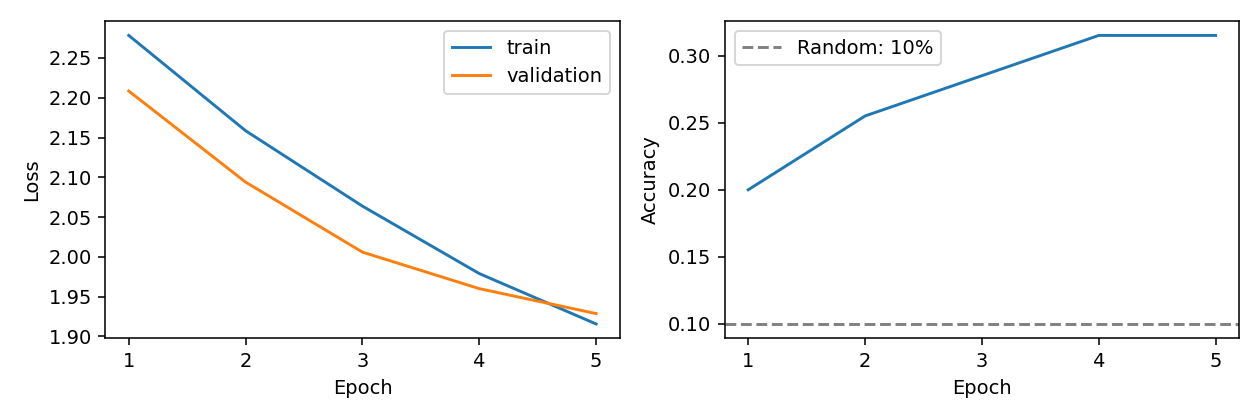

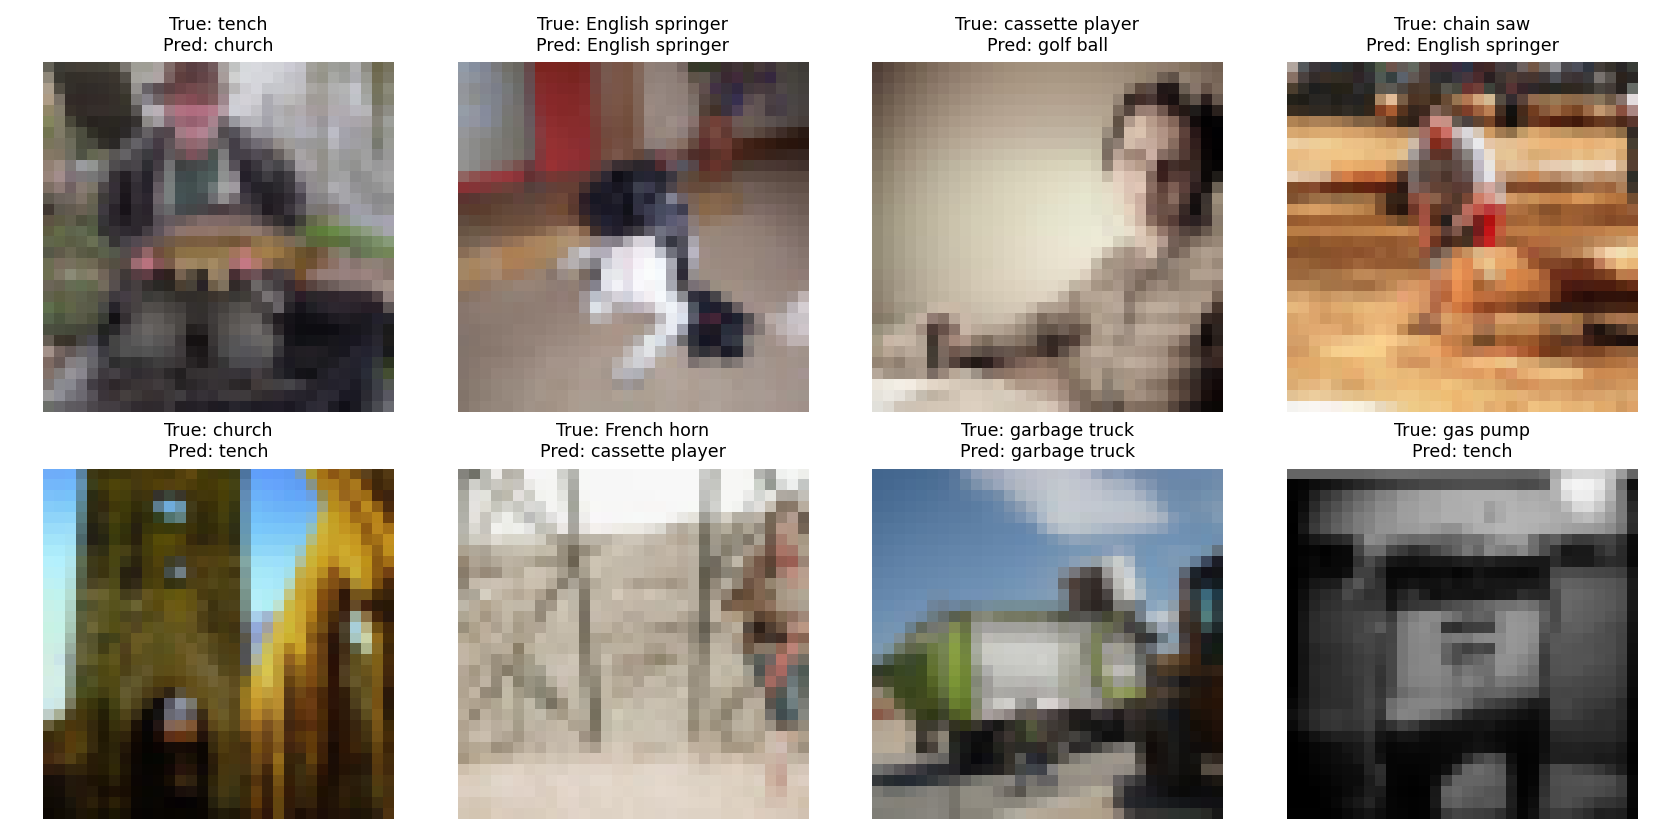

In [12]:
from IPython.display import display, Image
display(Image(filename=str(Path(OUTPUT_DIR) / "lenet" / "learning_curves.png")))
display(Image(filename=str(Path(OUTPUT_DIR) / "lenet" / "predictions.png")))

## 8. Train U-Net

Predictions may look smoother. A lower MSE means lower average pixel error, but does not guarantee better preservation of every visual detail.
If PSNR has not exceeded the baseline, record that the model is not yet better than leaving the image unchanged, then try more epochs.
The two-epoch quick mode primarily checks that the workflow runs.

In [13]:
unet, unet_report = run(
    "unet", train_data, val_data, class_names,
    epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED, output=OUTPUT_DIR,
    sigma=0.2
)

PyTorch 2.11.0; torchvision 0.26.0; CPU
unet: 29,779 parameters
No-processing baseline PSNR: 14.95 dB
Epoch 1/5: train=0.0715, val=0.0735, PSNR=11.34 dB, 0.8s
Epoch 2/5: train=0.0578, val=0.0509, PSNR=12.93 dB, 0.8s
Epoch 3/5: train=0.0347, val=0.0251, PSNR=16.01 dB, 0.8s
Epoch 4/5: train=0.0218, val=0.0183, PSNR=17.37 dB, 0.8s
Epoch 5/5: train=0.0182, val=0.0161, PSNR=17.94 dB, 0.8s
Saved best epoch 5 and plots in C:\Users\TooDou\Documents\python\ML\outputs\unet


Epoch 1/5: train=0.0715, val=0.0735, PSNR=11.34 dB, 1.0s


Epoch 2/5: train=0.0578, val=0.0509, PSNR=12.93 dB, 0.8s


Epoch 3/5: train=0.0347, val=0.0251, PSNR=16.01 dB, 0.9s


Epoch 4/5: train=0.0218, val=0.0183, PSNR=17.37 dB, 0.8s


Epoch 5/5: train=0.0182, val=0.0161, PSNR=17.94 dB, 0.8s


Saved best epoch 5 and plots in C:\Users\TooDou\.codex\.chatgpt-projects\g-p-6ab5d19ed3508191b6b71672a9f234a4\work\imagenet-cpu-tutorial-en\outputs\unet


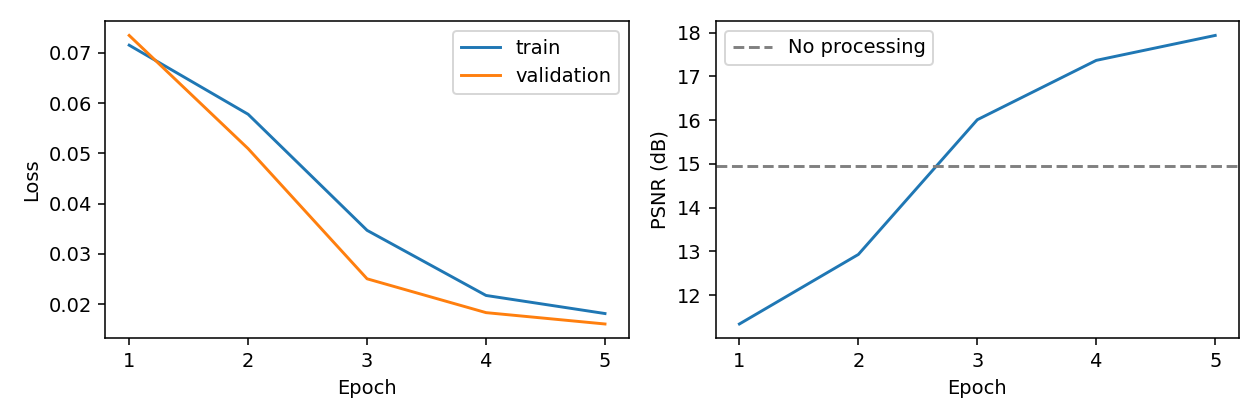

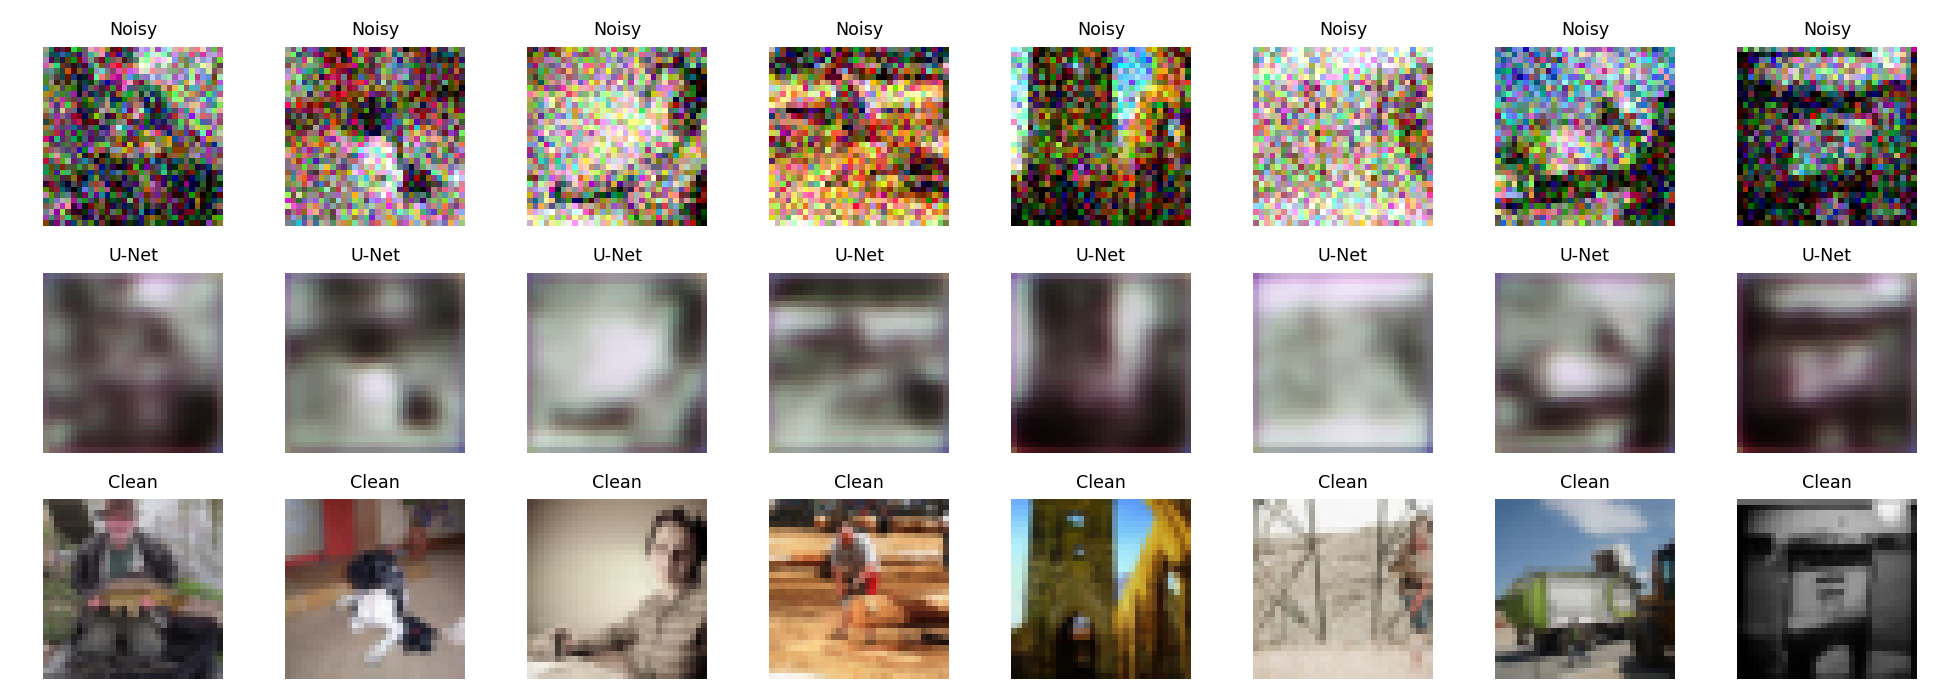

No-processing baseline: 14.95 dB
Best validation PSNR: 17.94 dB


In [14]:
display(Image(filename=str(Path(OUTPUT_DIR) / "unet" / "learning_curves.png")))
display(Image(filename=str(Path(OUTPUT_DIR) / "unet" / "predictions.png")))
print("No-processing baseline:", round(unet_report["baseline_psnr"], 2), "dB")
print("Best validation PSNR:", round(max(r["metric"] for r in unet_report["history"]), 2), "dB")

## 9. Reload the model and predict one image

Only load model files from sources you trust. Here we load weights we just saved ourselves.
Preprocessing must match training: 32×32 images, with [0,1] mapped to [-1,1] for classification.
The next cell uses a validation image. The following cell shows how to use your own photo.

In [15]:
checkpoint = torch.load(Path(OUTPUT_DIR) / "lenet" / "best.pt",
                        map_location="cpu", weights_only=True)
restored = LeNet()
restored.load_state_dict(checkpoint["state_dict"])
restored.eval()
image, true_label = val_data[0]
with torch.no_grad():
    probabilities = restored((image * 2 - 1).unsqueeze(0)).softmax(dim=1)[0]
predicted_label = probabilities.argmax().item()
print("True:", checkpoint["classes"][true_label.item()])
print("Predicted:", checkpoint["classes"][predicted_label])
print("Score:", round(probabilities[predicted_label].item(), 3))

True: tench
Predicted: church
Score: 0.185


In [16]:
# Uncomment and update the path when needed:
# from PIL import Image as PILImage
# transform = transforms.Compose([
#     transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor()
# ])
# with PILImage.open("my_photo.jpg") as photo:
#     image = transform(photo.convert("RGB"))
# with torch.no_grad():
#     probabilities = restored((image * 2 - 1).unsqueeze(0)).softmax(dim=1)[0]
# print(checkpoint["classes"][probabilities.argmax().item()])


The classifier knows only ten classes. It will still choose one of those classes for an unfamiliar object, and its softmax score is not necessarily a calibrated measure of confidence.

## 10. Exercises and experiment notes

Change one condition at a time. Use a new `OUTPUT_DIR` to preserve earlier results.

| Experiment | Change | What to observe |
|---|---|---|
| Train longer | 5 → 10 epochs | Do training and validation improve together? |
| Add data | 20 → 100 training images per class | Are validation results more stable? |
| Add stronger noise | sigma 0.2 → 0.3; retrain | Improvement relative to each experiment's own baseline |
| Switch to segmentation | Prepare image/mask pairs | Output class channels, CE or BCE loss, and IoU / Dice |

Do not update weights using validation data. This tutorial selects models using validation loss and has no separate test set, so the reported numbers are **validation results**.

Outputs include `best.pt`, `history.json`, learning curves, and prediction images. Save these files before ending a cloud session.

Full ImageNet data must be obtained separately; see [Torchvision ImageNet](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageNet.html). This tutorial only uses the ten-class Imagenette subset.